In [1]:
import cobra
import matplotlib.pyplot as plt
print(cobra.Configuration().solver)
import matplotlib.patches as mpatches
import numpy as np
from collections import defaultdict
#The above is to show me which solver will be used. 

model_path=r"C:\Users\cayle\OneDrive\Documents\Master's Reserach\MitoMammal Data\MitoMammal Coding Books\6_universal_mito_model.xml"
MitoMammal_model= cobra.io.read_sbml_model(model_path)

<module 'optlang.glpk_interface' from 'c:\\Users\\cayle\\miniconda3\\envs\\mitomammal\\lib\\site-packages\\optlang\\glpk_interface.py'>


In [2]:
ex_o2 = MitoMammal_model.reactions.get_by_id("EX_o2_e")

#Print summary
print("=" * 70)
print(f"Reaction ID:      {ex_o2.id}")
print(f"Name:             {ex_o2.name}")
print(f"Lower bound:      {ex_o2.lower_bound}")
print(f"Upper bound:      {ex_o2.upper_bound}")
print(f"Reaction equation: {ex_o2.reaction}")
print(f"Gene association:  {ex_o2.gene_reaction_rule}")
print(f"Subsystem:         {ex_o2.subsystem}")
print("=" * 70)

#Show stoichiometry
print("\nStoichiometry details:")
for met, coeff in ex_o2.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      EX_o2_e
Name:             EX_o2_e
Lower bound:      -1000.0
Upper bound:      1000.0
Reaction equation: o2_e <=> 
Gene association:  
Subsystem:         

Stoichiometry details:
  -1.0 o2_e (Oxygen)


In [3]:
O2 = MitoMammal_model.reactions.get_by_id("O2t")

#Print summary
print("=" * 70)
print(f"Reaction ID:      {O2.id}")
print(f"Name:             {O2.name}")
print(f"Lower bound:      {O2.lower_bound}")
print(f"Upper bound:      {O2.upper_bound}")
print(f"Reaction equation: {O2.reaction}")
print(f"Gene association:  {O2.gene_reaction_rule}")
print(f"Subsystem:         {O2.subsystem}")
print("=" * 70)

#Stoichiometry
print("\nStoichiometry details:")
for met, coeff in O2.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      O2t
Name:             R_O2t o2 transport (diffusion)
Lower bound:      0.0
Upper bound:      19.8
Reaction equation: o2_e --> o2_c
Gene association:  
Subsystem:         Boundary conditions - core

Stoichiometry details:
  -1.0 o2_e (Oxygen)
  +1.0 o2_c (Oxygen)


In [4]:

glct = MitoMammal_model.reactions.get_by_id("GLCt1r")

print("=" * 70)
print(f"Reaction ID:      {glct.id}")
print(f"Name:             {glct.name}")
print(f"Lower bound:      {glct.lower_bound}")
print(f"Upper bound:      {glct.upper_bound}")
print(f"Reaction equation: {glct.reaction}")
print(f"Gene association:  {glct.gene_reaction_rule}")
print(f"Subsystem:         {glct.subsystem}")
print("=" * 70)

Reaction ID:      GLCt1r
Name:             R_GLCt1r glucose transport
Lower bound:      -1000.0
Upper bound:      0.9
Reaction equation: glc_D_e <=> glc_D_c
Gene association:  
Subsystem:         Boundary conditions - core


In [5]:


ex_glc = MitoMammal_model.reactions.get_by_id("EX_glc_D_e")

print("=" * 70)
print(f"Reaction ID:      {ex_glc.id}")
print(f"Name:             {ex_glc.name}")
print(f"Lower bound:      {ex_glc.lower_bound}")
print(f"Upper bound:      {ex_glc.upper_bound}")
print(f"Reaction equation: {ex_glc.reaction}")
print(f"Gene association:  {ex_glc.gene_reaction_rule}")
print(f"Subsystem:         {ex_glc.subsystem}")
print("=" * 70)

print("\nStoichiometry details:")
for met, coeff in ex_glc.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      EX_glc_D_e
Name:             EX_glc_D_e
Lower bound:      -1000.0
Upper bound:      1000.0
Reaction equation: glc_D_e <=> 
Gene association:  
Subsystem:         

Stoichiometry details:
  -1.0 glc_D_e (D-Glucose)


In [6]:
met = MitoMammal_model.metabolites.atp_c
print(met.summary().to_string())

atp_c
=====
Formula: C10H12N5O13P3

Producing Reactions
-------------------
Percent  Flux       Reaction                                                Definition
 96.41% 99.93 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  1.75%  1.81            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  1.84% 1.906            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent    Flux       Reaction                                          Definition
  0.45% -0.4697           ADK1                         amp_c + atp_c <=> 2.0 adp_c
  0.45% -0.4697     FACOAL160i atp_c + coa_c + hdca_c --> amp_c + pmtcoa_c + ppi_c
  0.01%   -0.01           GLYK           atp_c + glyc_c --> adp_c + glyc3p_c + h_c
  0.87%    -0.9           HEX1             atp_c + glc_D_c --> adp_c + g6p_c + h_c
 97.35%  -100.9 OF_ATP_mitoMap    atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  0.87%    -0.9            PFK       

In [7]:
for rxn in MitoMammal_model.reactions:
    if "exchange" in rxn.name.lower() or rxn.id.startswith("EX"):
        print(rxn.id, rxn.name)


EX_2hb_e EX_2hb_e
EX_ac_e EX_ac_e
EX_acac_e EX_acac_e
EX_akg_e EX_akg_e
EX_ala_B_e EX_ala_B_e
EX_ala_L_e EX_ala_L_e
EX_arg_L_e EX_arg_L_e
EX_argsuc_e EX_argsuc_e
EX_asn_L_e EX_asn_L_e
EX_asp_L_e EX_asp_L_e
EX_bhb_e EX_bhb_e
EX_bilirub_e EX_bilirub_e
EX_biomass_e EX_biomass_e
EX_but_e EX_but_e
EX_chol_e EX_chol_e
EX_cit_e EX_cit_e
EX_citr_L_e EX_citr_L_e
EX_co_e EX_co_e
EX_co2_e EX_co2_e
EX_creat_e EX_creat_e
EX_cyan_e EX_cyan_e
EX_cys_L_e EX_cys_L_e
EX_etoh_e EX_etoh_e
EX_fe2_e EX_fe2_e
EX_for_e EX_for_e
EX_fum_e EX_fum_e
EX_glc_D_e EX_glc_D_e
EX_gln_L_e EX_gln_L_e
EX_glu_L_e EX_glu_L_e
EX_gly_e EX_gly_e
EX_glyc_e EX_glyc_e
EX_h_e EX_h_e
EX_h2o_e EX_h2o_e
EX_HC00250_e EX_HC00250_e
EX_hco3_e EX_hco3_e
EX_hdca_e EX_hdca_e
EX_his_L_e EX_his_L_e
EX_icit_e EX_icit_e
EX_ile_L_e EX_ile_L_e
EX_lac_L_e EX_lac_L_e
EX_leu_L_e EX_leu_L_e
EX_lys_L_e EX_lys_L_e
EX_mal_L_e EX_mal_L_e
EX_mercplac_e EX_mercplac_e
EX_met_L_e EX_met_L_e
EX_nad_e EX_nad_e
EX_nadh_e EX_nadh_e
EX_nh4_e EX_nh4_e
EX_no_e EX_n

In [8]:
oxygen = MitoMammal_model.metabolites.o2_c
print(oxygen.summary().to_string())

o2_c
====
Formula: O2

Producing Reactions
-------------------
Percent Flux Reaction    Definition
100.00% 19.8      O2t o2_e --> o2_c

Consuming Reactions
-------------------
Percent  Flux Reaction    Definition
100.00% -19.8     O2tm o2_c <=> o2_m


In [9]:
gluc = MitoMammal_model.metabolites.glc_D_c
print(gluc.summary().to_string())

glc_D_c
Formula: C6H12O6

Producing Reactions
-------------------
Percent Flux Reaction          Definition
100.00%  0.9   GLCt1r glc_D_e <=> glc_D_c

Consuming Reactions
-------------------
Percent Flux Reaction                              Definition
100.00% -0.9     HEX1 atp_c + glc_D_c --> adp_c + g6p_c + h_c


In [10]:
#preparing to run pfba 
from cobra.flux_analysis import pfba

In [11]:
#lower bound 0, for no nurtient uptake. 
#upper bound 1000 for secretion of metabolites. 
for rxn in MitoMammal_model.exchanges:
    rxn.lower_bound= 0
    rxn.upper_bound= 1000

input_glc_exchange= MitoMammal_model.reactions.get_by_id('EX_glc_D_e')
input_02_exchange= MitoMammal_model.reactions.get_by_id('EX_o2_e')
   

In [12]:
#attempts at constraining glucose uptake to 1 moelcule 
input_glc_exchange.lower_bound= -1
input_glc_exchange.upper_bound= -1

#excess oxygen, so that it does not become a limiting factor 
input_02_exchange.lower_bound= -1000
input_02_exchange.upper_bound= 1000

In [13]:
#Changing the upper flux bound of the GLCt1r glucose transporter reaction
#So that glucose uptake into mitochondria is not fixed at 0.9
glct = MitoMammal_model.reactions.get_by_id("GLCt1r")
glct.upper_bound = 1000
print(glct.bounds)

#confirming the flux bounds for glucose uptake and secretion 
glc = MitoMammal_model.reactions.get_by_id("EX_glc_D_e")
print(glc.bounds)

(-1000.0, 1000)
(-1, -1)


In [14]:
#confirming the objective function 
print(MitoMammal_model.objective)

Maximize
1.0*OF_ATP_mitoMap - 1.0*OF_ATP_mitoMap_reverse_44b94


In [15]:
solution = MitoMammal_model.optimize()
print(solution)

<Solution 32.773 at 0x18bf22e4cd0>


In [16]:
met = MitoMammal_model.metabolites.atp_c
print(met.summary().to_string())

atp_c
=====
Formula: C10H12N5O13P3

Producing Reactions
-------------------
Percent  Flux       Reaction                                                Definition
 88.51% 30.78 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  5.75% 1.998            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  5.75% 1.998            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent    Flux       Reaction                                               Definition
  0.03%   -0.01          ACITL atp_c + cit_c + coa_c --> accoa_c + adp_c + oaa_c + pi_c
  2.88%      -1           HEX1                  atp_c + glc_D_c --> adp_c + g6p_c + h_c
 94.23%  -32.77 OF_ATP_mitoMap         atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  2.87% -0.9983            PFK                    atp_c + f6p_c --> adp_c + fdp_c + h_c


In [17]:
met_nadc = MitoMammal_model.metabolites.nad_c
print(met_nadc.summary().to_string())

nad_c
=====
Formula: C21H26N7O14P2

Producing Reactions
-------------------
Percent     Flux Reaction                               Definition
  0.49% 0.009825    LDH_L lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    1.989      MDH mal_L_c + nad_c <=> h_c + nadh_c + oaa_c

Consuming Reactions
-------------------
Percent   Flux Reaction                                      Definition
100.00% -1.998     GAPD g3p_c + nad_c + pi_c <=> 13dpg_c + h_c + nadh_c


In [18]:
met_nadhc = MitoMammal_model.metabolites.nadh_c
print(met_nadhc.summary().to_string())

nadh_c
Formula: C21H27N7O14P2

Producing Reactions
-------------------
Percent  Flux Reaction                                      Definition
100.00% 1.998     GAPD g3p_c + nad_c + pi_c <=> 13dpg_c + h_c + nadh_c

Consuming Reactions
-------------------
Percent      Flux Reaction                               Definition
  0.49% -0.009825    LDH_L lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    -1.989      MDH mal_L_c + nad_c <=> h_c + nadh_c + oaa_c


In [19]:
met_pyrc = MitoMammal_model.metabolites.pyr_c
print(met_pyrc.summary().to_string())

pyr_c
=====
Formula: C3H3O3

Producing Reactions
-------------------
Percent  Flux Reaction                            Definition
100.00% 1.998      PYK adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent      Flux Reaction                                            Definition
  0.49% -0.009825    LDH_L              lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    -1.989   PYRt2m 0.18 PMF_c + h_c + pyr_c --> 0.18 PMF_m + h_m + pyr_m


In [20]:
met_adp = MitoMammal_model.metabolites.adp_c
print(met_adp.summary().to_string())

adp_c
=====
Formula: C10H12N5O10P2

Producing Reactions
-------------------
Percent   Flux       Reaction                                               Definition
  0.03%   0.01          ACITL atp_c + cit_c + coa_c --> accoa_c + adp_c + oaa_c + pi_c
  2.88%      1           HEX1                  atp_c + glc_D_c --> adp_c + g6p_c + h_c
 94.23%  32.77 OF_ATP_mitoMap         atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  2.87% 0.9983            PFK                    atp_c + f6p_c --> adp_c + fdp_c + h_c

Consuming Reactions
-------------------
Percent   Flux       Reaction                                                Definition
 88.51% -30.78 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  5.75% -1.998            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  5.75% -1.998            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c


In [21]:
met_biomass = MitoMammal_model.metabolites.biomass_c
print(met_biomass.summary().to_string())

biomass_c
Formula: BIOMASS

Producing Reactions
-------------------
Percent  Flux       Reaction                                       Definition
100.00% 32.77 OF_ATP_mitoMap atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c

Consuming Reactions
-------------------
Percent   Flux        Reaction              Definition
100.00% -32.77 Biomass_mitoMap biomass_e <-- biomass_c


In [22]:
gluc = MitoMammal_model.metabolites.glc_D_c
print(gluc.summary().to_string())

glc_D_c
Formula: C6H12O6

Producing Reactions
-------------------
Percent Flux Reaction          Definition
100.00%    1   GLCt1r glc_D_e <=> glc_D_c

Consuming Reactions
-------------------
Percent Flux Reaction                              Definition
100.00%   -1     HEX1 atp_c + glc_D_c --> adp_c + g6p_c + h_c


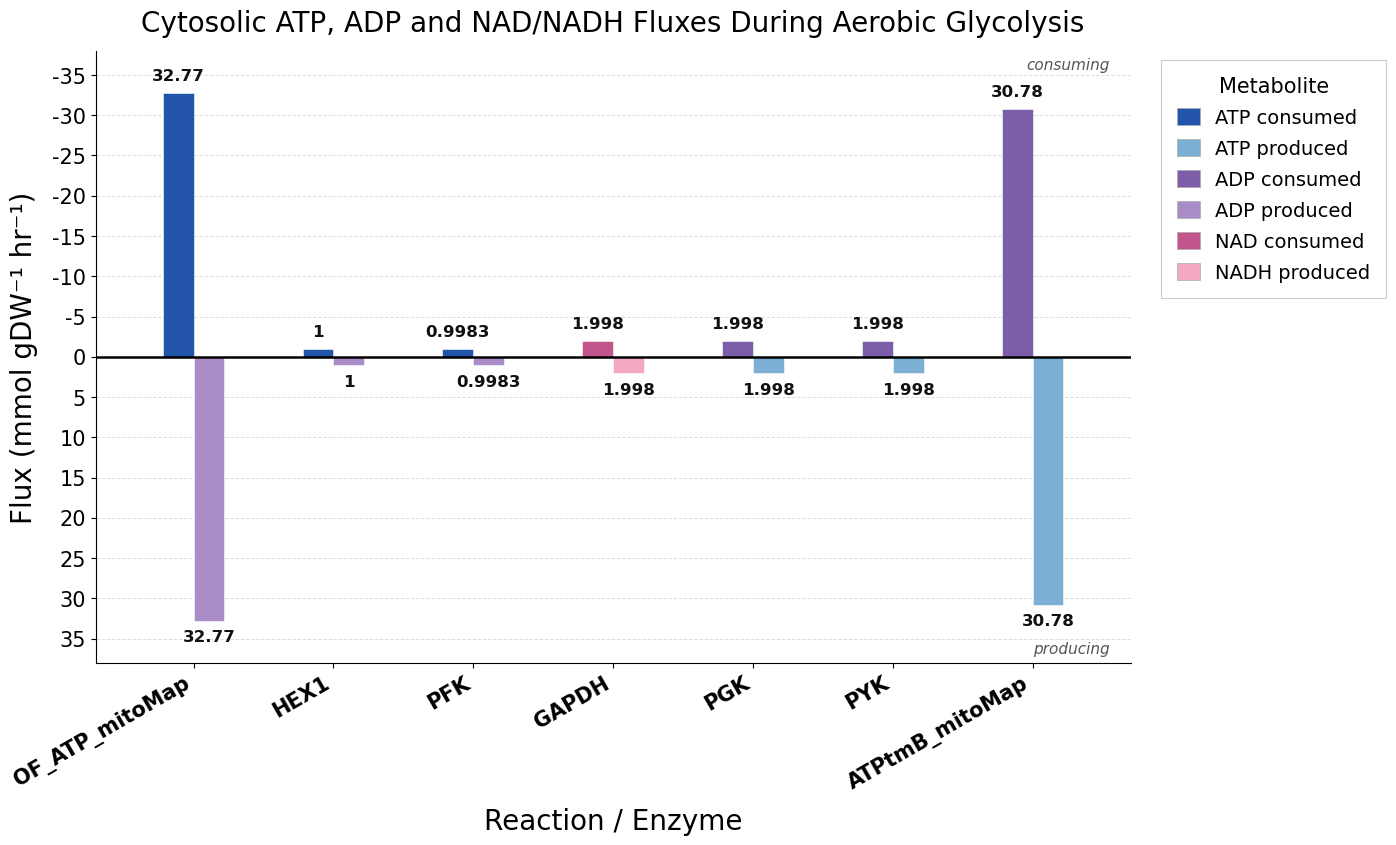

In [31]:


reactions = [
    'OF_ATP_mitoMap', 'HEX1', 'PFK', 'GAPDH',
    'PGK', 'PYK', 'ATPtmB_mitoMap',
]

data = [
    ('OF_ATP_mitoMap', 'atp_consumed',  -32.77),
    ('OF_ATP_mitoMap', 'adp_produced',   32.77),
    ('HEX1',           'atp_consumed',   -1.0),
    ('HEX1',           'adp_produced',    1.0),
    ('PFK',            'atp_consumed',   -0.9983),
    ('PFK',            'adp_produced',    0.9983),
    ('GAPDH',          'nad_consumed',   -1.998),
    ('GAPDH',          'nadh_produced',   1.998),
    ('PGK',            'adp_consumed',   -1.998),
    ('PGK',            'atp_produced',    1.998),
    ('PYK',            'adp_consumed',   -1.998),
    ('PYK',            'atp_produced',    1.998),
    ('ATPtmB_mitoMap', 'adp_consumed',  -30.78),
    ('ATPtmB_mitoMap', 'atp_produced',   30.78),
]

colours = {
    'atp_consumed':  '#2255AA',
    'atp_produced':  '#7BAFD4',
    'adp_produced':  '#A98CC8',
    'adp_consumed':  '#7B5EA7',
    'nad_consumed':  '#C2558B',
    'nadh_produced': '#F4A7C3',
}
legend_labels = {
    'atp_consumed':  'ATP consumed',
    'atp_produced':  'ATP produced',
    'adp_consumed':  'ADP consumed',
    'adp_produced':  'ADP produced',
    'nad_consumed':  'NAD consumed',
    'nadh_produced': 'NADH produced',
}

fig, ax = plt.subplots(figsize=(15, 9))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
fig.subplots_adjust(left=0.09, right=0.78, top=0.88, bottom=0.20)

x_positions = {rxn: i for i, rxn in enumerate(reactions)}
bar_width = 0.22

ax.set_ylim(38, -38)

reaction_bars = defaultdict(list)
for rxn, met_type, flux in data:
    reaction_bars[rxn].append((met_type, flux))

for rxn, bars in reaction_bars.items():
    x_base = x_positions[rxn]
    n = len(bars)
    offsets = np.linspace(-(n-1)*bar_width/2, (n-1)*bar_width/2, n)

    for (met_type, flux), x_off in zip(bars, offsets):
        ax.bar(x_base + x_off, flux,
               width=bar_width,
               color=colours[met_type],
               edgecolor='white', linewidth=0.4, zorder=3)
        gap = 3.0
        fmt = f'{abs(flux):.2f}' if abs(flux) >= 10 else f'{abs(flux):.4g}'

        if flux < 0:           
            y_txt = flux - gap
            va    = 'top'
        else:                  
            y_txt = flux + gap
            va    = 'bottom'

        ax.text(x_base + x_off, y_txt, fmt,
                ha='center', va=va,
                fontsize=12, color='#111111', fontweight='bold',
                zorder=6, clip_on=False)

ax.axhline(0, color='black', linewidth=1.8, zorder=4)
ax.set_xticks(range(len(reactions)))
ax.set_xticklabels(reactions, rotation=30, ha='right',
                   fontsize=15, fontweight='bold')
ax.set_xlim(-0.7, len(reactions) - 0.3)

yticks = np.arange(-35, 36, 5)
ax.set_yticks(yticks)
ax.set_yticklabels([str(int(v)) for v in yticks], fontsize=15)

ax.set_ylabel('Flux (mmol gDW⁻¹ hr⁻¹)', fontsize=20, labelpad=10)
ax.set_xlabel('Reaction / Enzyme', fontsize=20, labelpad=10)
ax.set_title(
    'Cytosolic ATP, ADP and NAD/NADH Fluxes During Aerobic Glycolysis',
    fontsize=20, fontweight='500', pad=14,
)

ax.yaxis.grid(True, color='#DDDDDD', linestyle='--', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.text(0.98, 0.99,
        'consuming',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=11, color='#555555', fontstyle='italic')

ax.text(0.98, 0.01,
        'producing',
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=11, color='#555555', fontstyle='italic')

legend_order = [
    'atp_consumed', 'atp_produced',
    'adp_consumed', 'adp_produced',
    'nad_consumed', 'nadh_produced',
]
patches = [
    mpatches.Patch(facecolor=colours[k], edgecolor='#AAAAAA',
                   linewidth=0.5, label=legend_labels[k])
    for k in legend_order
]
legend = ax.legend(
    handles=patches,
    title='Metabolite',
    title_fontsize=15,
    fontsize=14,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    bbox_transform=ax.transAxes,
    frameon=True, framealpha=1.0,
    edgecolor='#CCCCCC',
    fancybox=False,
    borderpad=0.8, labelspacing=0.6,
    handlelength=1.2, handleheight=1.0,
)
legend.get_frame().set_linewidth(0.8)



